<center><h1>Kavle_Anirudh_HW6</h1></center>

Name: Anirudh Kavle
<br>
Github Username: Anirudh-Kavle
<br>
USC ID: 6327535963
<br>
Email ID: kavle@usc.edu

## 1. Tree-Based Methods

Import packages

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import (confusion_matrix, roc_curve, roc_auc_score,
                             ConfusionMatrixDisplay)
from imblearn.ensemble import BalancedRandomForestClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from xgboost import XGBClassifier

SEED = 42


class BatchMedianImputer(TransformerMixin, BaseEstimator):
    # footnote 1: every batch (training set, test set, CV validation fold)
    # is filled with its own medians
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        A = np.array(X, dtype=float)
        rows, cols = np.where(np.isnan(A))
        A[rows, cols] = np.nanmedian(A, axis=0)[cols]
        assert not np.isnan(A).any(), 'a feature is entirely missing'
        return A


def report(name, model, X_tr, y_tr, X_te, y_te):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    rows = {}
    splits = [(axes[0], 'Train', X_tr, y_tr),
              (axes[1], 'Test', X_te, y_te)]
    for ax, split, X, y in splits:
        p = model.predict_proba(X)[:, 1]
        cm = confusion_matrix(y, p >= 0.5)
        ConfusionMatrixDisplay(cm, display_labels=['neg', 'pos']).plot(
            ax=ax, colorbar=False, values_format='d')
        ax.set_title(f'{split} confusion matrix')
        fpr, tpr, _ = roc_curve(y, p)
        auc = roc_auc_score(y, p)
        axes[2].plot(fpr, tpr, label=f'{split} (AUC = {auc:.4f})')
        err = (cm[0, 1] + cm[1, 0]) / len(y)
        rows[split] = {'FP': cm[0, 1], 'FN': cm[1, 0],
                       'Misclassification': err, 'AUC': auc}
    axes[2].plot([0, 1], [0, 1], 'k:')
    axes[2].set(xlabel='False positive rate', ylabel='True positive rate',
                title='ROC curves')
    axes[2].legend(loc='lower right')
    fig.suptitle(name)
    plt.tight_layout()
    plt.show()
    return pd.DataFrame(rows).T.astype({'FP': int, 'FN': int})


def compare(models, est_label):
    table = {}
    for name, (r, est) in models.items():
        table[name] = {'Train error': r.loc['Train', 'Misclassification'],
                       est_label: est,
                       'Test error': r.loc['Test', 'Misclassification'],
                       'Train AUC': r.loc['Train', 'AUC'],
                       'Test AUC': r.loc['Test', 'AUC'],
                       'Test FP': r.loc['Test', 'FP'],
                       'Test FN': r.loc['Test', 'FN']}
    return pd.DataFrame(table).T.astype({'Test FP': int, 'Test FN': int})

### (a) Download the APS Failure data

In [2]:
train = pd.read_csv('../data/aps_failure_training_set.csv',
                    skiprows=20, na_values='na')
test = pd.read_csv('../data/aps_failure_test_set.csv',
                   skiprows=20, na_values='na')
X_train, X_test = train.drop(columns='class'), test.drop(columns='class')
y_train = (train['class'] == 'pos').astype(int).to_numpy()
y_test = (test['class'] == 'pos').astype(int).to_numpy()
print('Training set:', train.shape, '  Test set:', test.shape)
train.head()

Training set: (60000, 171)   Test set: (16000, 171)


,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,...,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0,...,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,...,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,neg,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,...,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,neg,60874,NaN,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,...,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0


### (b) Data Preparation

#### (i) Research what types of techniques are usually used

Common techniques for dealing with missing values:

- Deletion: drop the rows (or columns) that have missing values. It's simple, but it throws data away and can bias the results if values aren't missing at random.
- Simple imputation: replace each missing value with the feature's mean, median or most frequent value.
- Model-based imputation: predict the missing values from the other features, e.g. k-nearest-neighbour imputation or iterative (MICE-style) regression imputation. Multiple imputation repeats this several times to reflect the uncertainty in the filled-in values.
- Missing-value indicators: add a 0/1 column that marks where a value was missing, usually together with one of the imputations above.
- Models that handle missing values themselves, e.g. XGBoost learns a default direction for missing values at each split.

Deletion isn't an option here: the output below shows that only 591 of the 60,000 training rows have no missing values. I use median imputation. The features are counts and histogram bins with a few extremely large values (see the CVs in (ii)), and unlike the mean, the median isn't pulled around by those values. It also gives complete data for every model and for SMOTE in (f).

Following footnote 1, the training set is filled with training medians and the test set with test medians. I also apply this convention separately to each CV validation fold, so predictions depend on the batch being transformed. The `BatchMedianImputer` defined above does this.

In [3]:
n_missing = X_train.isna().sum().sum()
print('Missing values in the training set:', n_missing,
      f'({X_train.isna().mean().mean():.1%} of all entries)')
print('Training rows with no missing values:',
      X_train.notna().all(axis=1).sum(), 'of', len(X_train))

X_train_imp = pd.DataFrame(BatchMedianImputer().fit_transform(X_train),
                           columns=X_train.columns)
print('Missing values after median imputation:',
      X_train_imp.isna().sum().sum())

Missing values in the training set: 850015 (8.3% of all entries)
Training rows with no missing values: 591 of 60000
Missing values after median imputation: 0


#### (ii) Calculate the coefficient of variation

In [4]:
cv = X_train_imp.std(ddof=1) / X_train_imp.mean()
cv = cv.sort_values(ascending=False)
blocks = [cv.iloc[i:i + 34].round(3).reset_index()
          .set_axis(['Feature', 'CV'], axis=1)
          for i in range(0, 170, 34)]
pd.concat(blocks, axis=1)

,Feature,CV,Feature,CV,Feature,CV,Feature,CV,Feature,CV
0,cf_000,244.888,ay_003,28.735,be_000,6.847,cs_003,3.132,bb_000,2.405
1,co_000,244.507,cn_000,26.336,ba_008,6.831,ap_000,3.081,bu_000,2.405
2,ad_000,244.323,ae_000,24.200,cn_002,6.707,dd_000,3.057,bv_000,2.405
3,cs_009,237.931,at_000,23.708,cu_000,6.673,ck_000,3.056,cq_000,2.405
4,dh_000,123.216,az_008,22.680,cn_007,6.335,ay_006,3.053,ci_000,2.400
5,dj_000,117.494,dq_000,22.030,bz_000,6.314,az_005,3.035,ed_000,2.394
6,ag_000,92.918,af_000,19.471,db_000,6.259,ba_006,3.031,ag_006,2.357
7,as_000,87.332,ai_000,18.204,ag_008,6.221,bi_000,3.022,cn_005,2.345
8,ay_009,84.734,ag_002,17.566,av_000,6.006,ag_005,2.956,ds_000,2.320
9,ak_000,80.425,az_007,16.229,ee_009,5.692,du_000,2.918,ah_000,2.312


#### (iii) Plot a correlation matrix

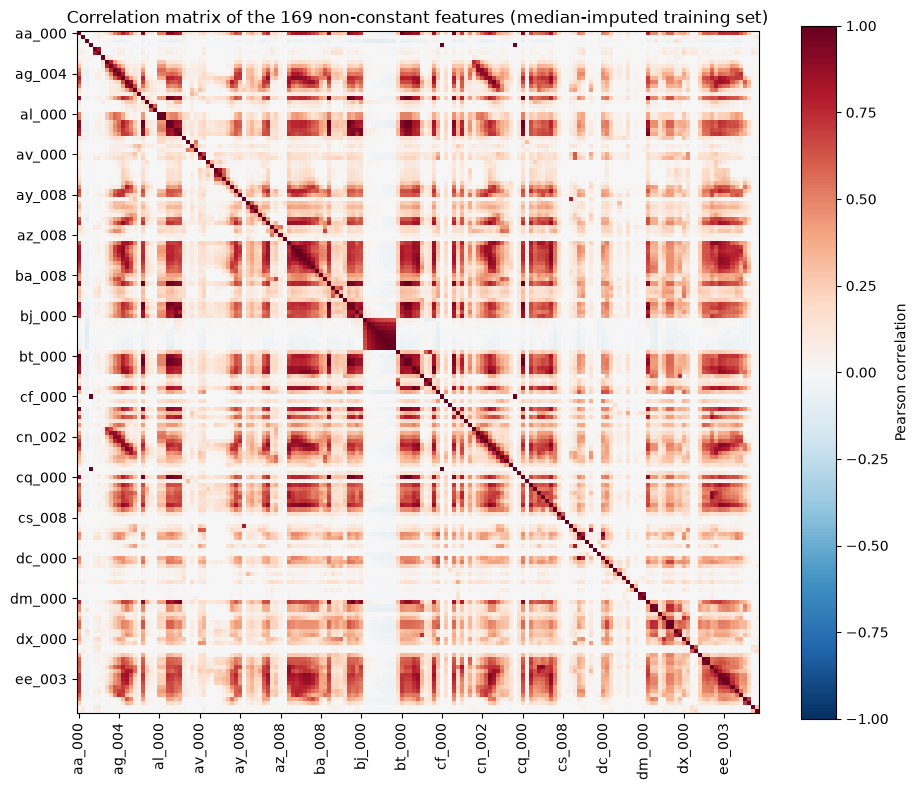

In [5]:
# cd_000 is constant (CV = 0), so its correlations are undefined
corr = X_train_imp.drop(columns='cd_000').corr()
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ticks = np.arange(0, len(corr), 10)
ax.set_xticks(ticks, corr.columns[ticks], rotation=90)
ax.set_yticks(ticks, corr.columns[ticks])
fig.colorbar(im, ax=ax, label='Pearson correlation')
ax.set_title('Correlation matrix of the 169 non-constant features '
             '(median-imputed training set)')
plt.show()

`cd_000` is left out because it's constant (its CV is 0 in (ii)), so its correlation with other features is undefined.

Most of the matrix is light, meaning weak correlation, but there are several large dark-red blocks of features that are strongly positively correlated with each other. The clearest is the solid square around `bj_000` to `bt_000`, and there are wide red bands across the `az_`, `ba_`, `cn_` and `ee_` histogram features. There's almost no blue, so strong negative correlations are rare. Many of the features carry overlapping information.

#### (iv) Make scatter plots and box plots

13 features with the highest CV: ['cf_000', 'co_000', 'ad_000', 'cs_009', 'dh_000', 'dj_000', 'ag_000', 'as_000', 'ay_009', 'ak_000', 'az_009', 'ch_000', 'au_000']


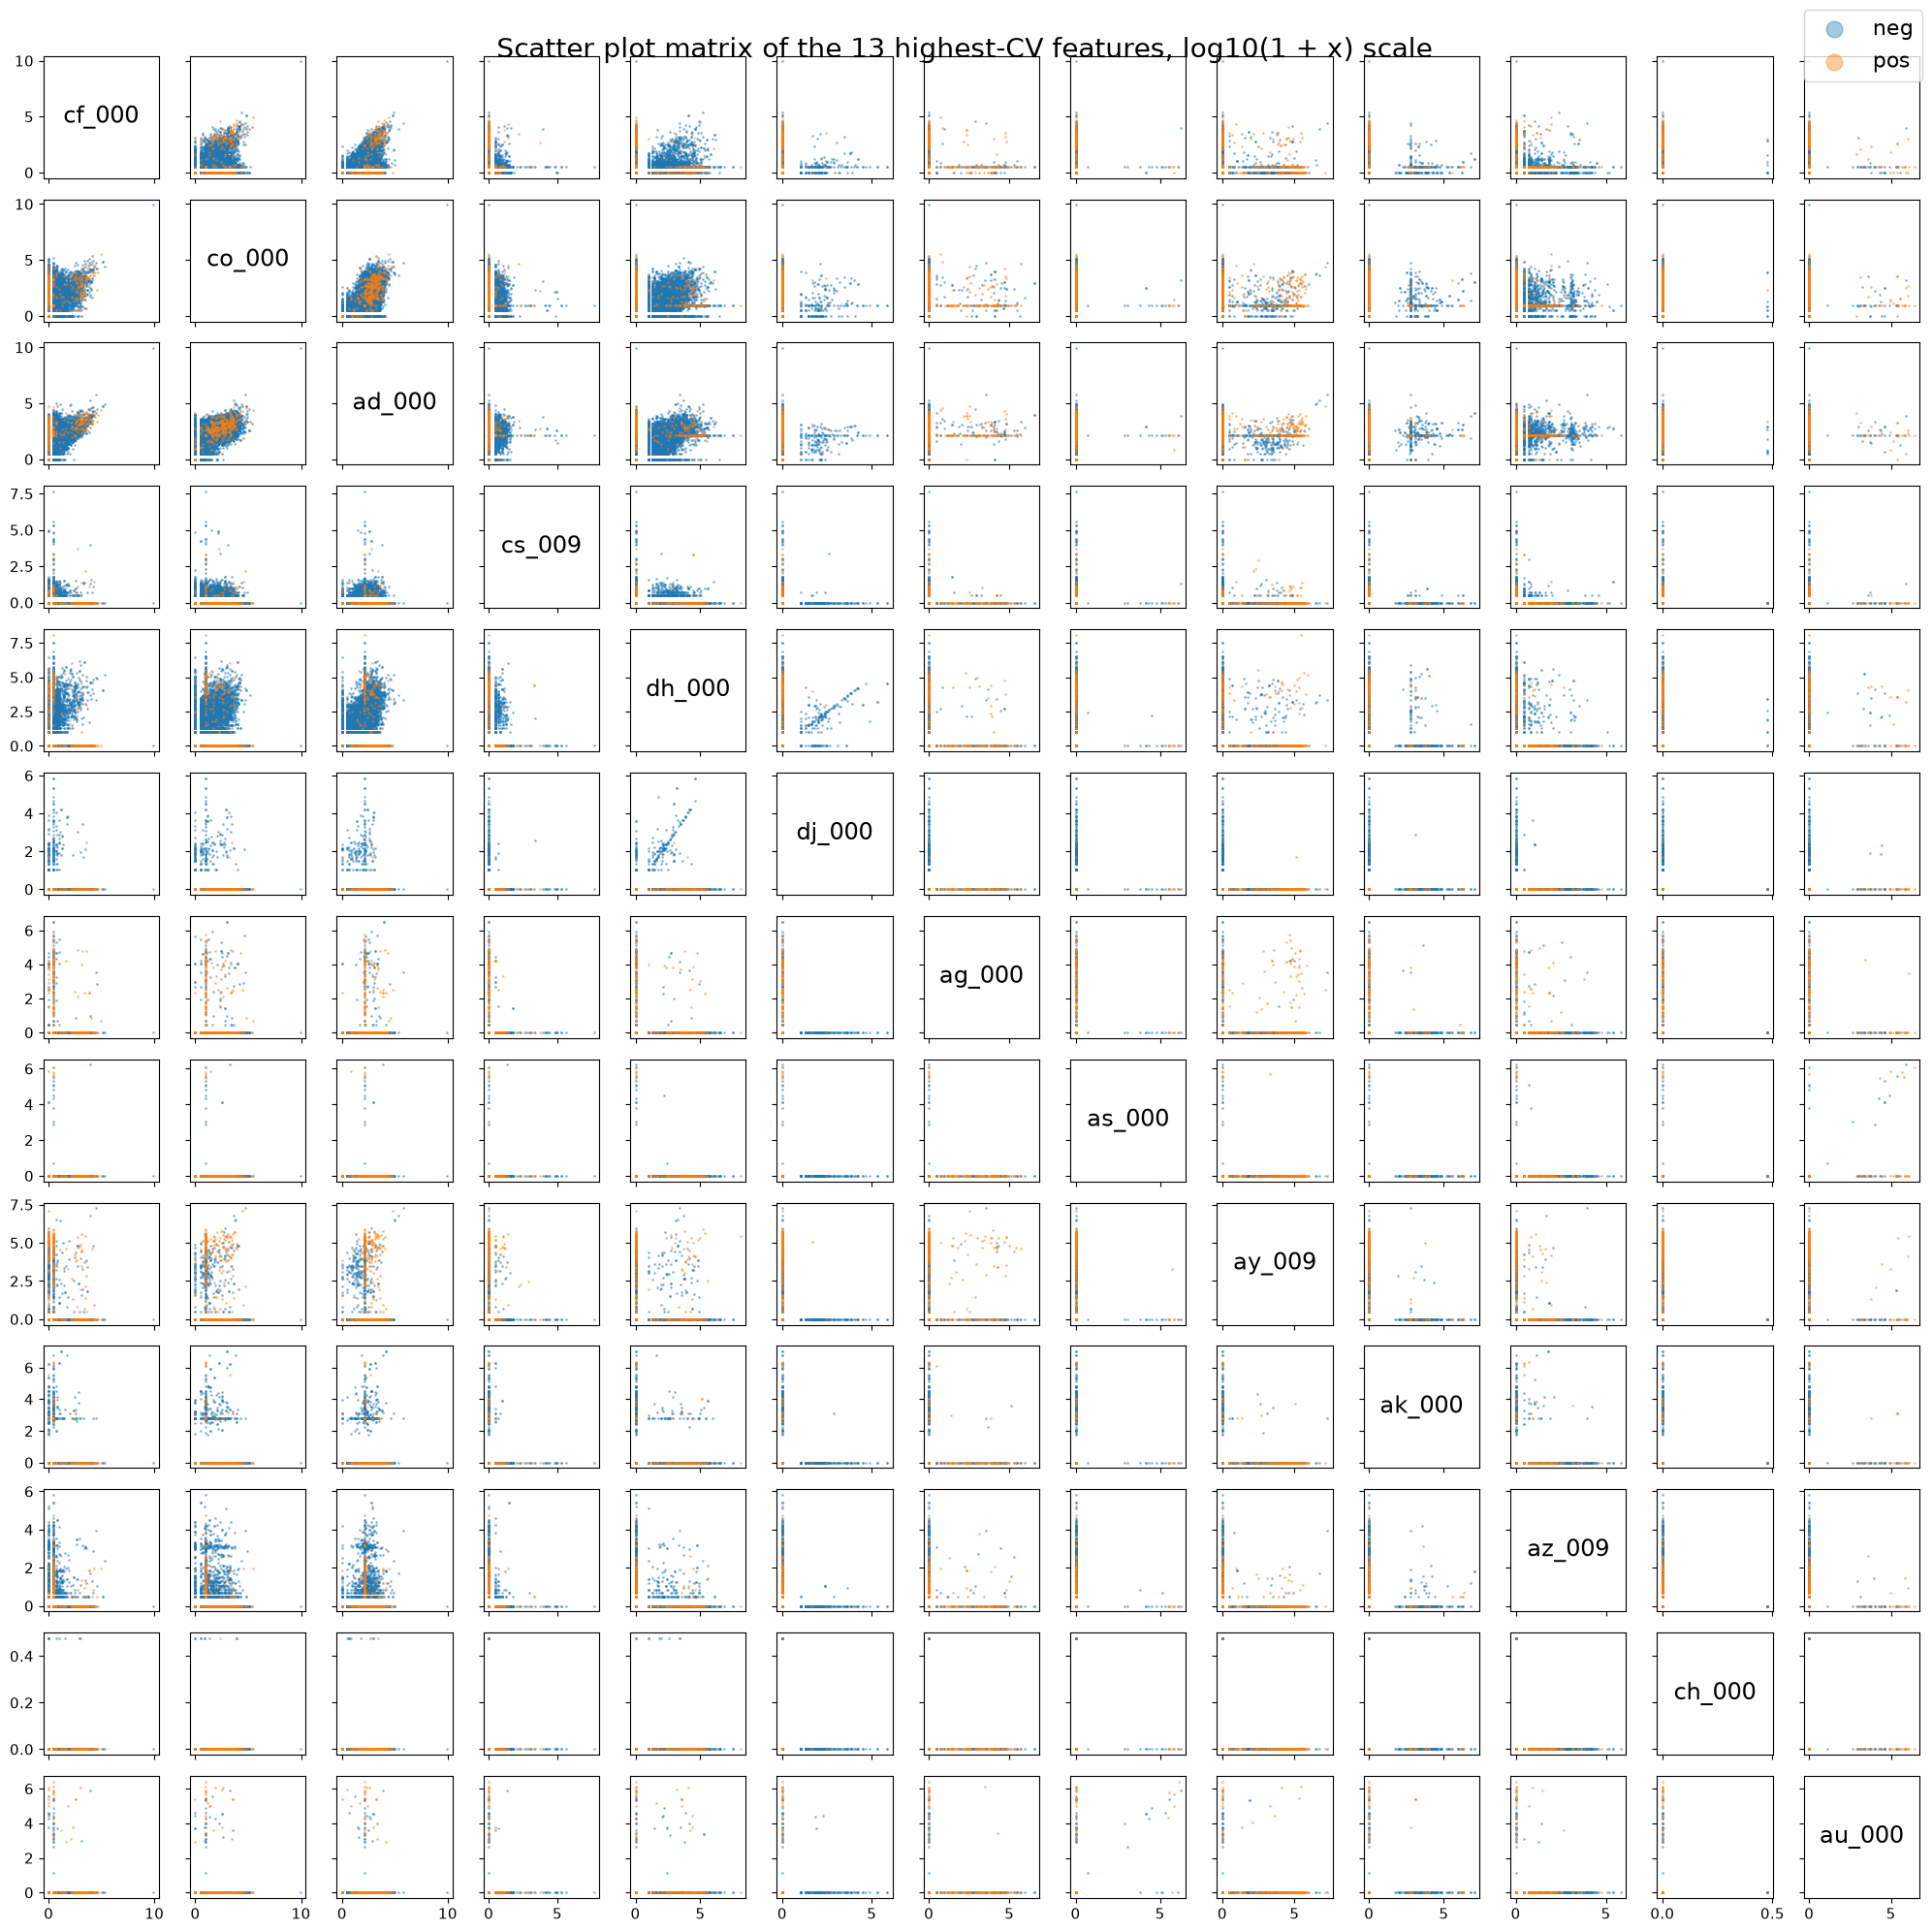

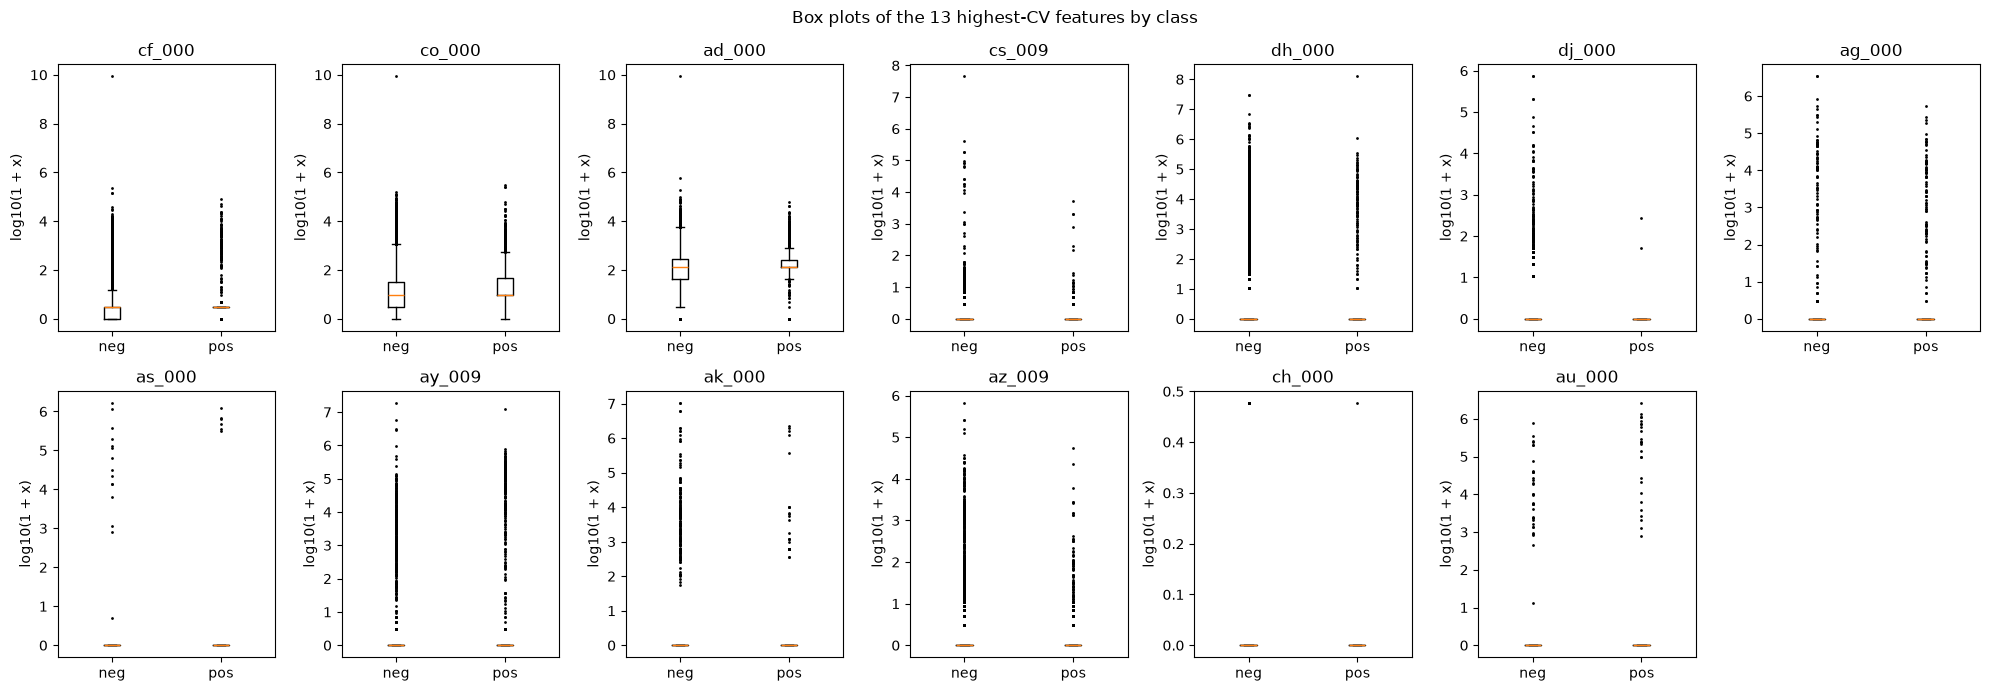

In [6]:
top = cv.index[:int(np.floor(np.sqrt(170)))].tolist()
print('13 features with the highest CV:', top)

# log10(1 + x) for display only; the models use the raw values
L = np.log10(1 + X_train_imp[top])
k = len(top)
fig, axes = plt.subplots(k, k, figsize=(20, 20),
                         sharex='col', sharey='row')
for i in range(k):
    for j in range(k):
        ax = axes[i, j]
        ax.tick_params(labelsize=11)
        if i == j:
            ax.text(0.5, 0.5, top[i], transform=ax.transAxes,
                    ha='center', va='center', fontsize=17)
            continue
        for label, color, name in [(0, 'tab:blue', 'neg'),
                                   (1, 'tab:orange', 'pos')]:
            m = y_train == label
            ax.scatter(L.iloc[:, j][m], L.iloc[:, i][m], s=1, alpha=0.4,
                       color=color, label=name, rasterized=True)
fig.legend(*axes[0, 1].get_legend_handles_labels(), loc='upper right',
           markerscale=12, fontsize=16)
fig.suptitle('Scatter plot matrix of the 13 highest-CV features, '
             'log10(1 + x) scale', fontsize=20)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 7, figsize=(20, 7))
for ax, f in zip(axes.ravel(), top):
    ax.boxplot([L.loc[y_train == 0, f], L.loc[y_train == 1, f]],
               flierprops={'markersize': 1})
    ax.set_xticks([1, 2], ['neg', 'pos'])
    ax.set(title=f, ylabel='log10(1 + x)')
axes[-1, -1].axis('off')
fig.suptitle('Box plots of the 13 highest-CV features by class')
plt.tight_layout()
plt.show()

Most of these 13 features are 0 for most trucks, with a long tail of very large values, which is why their CVs are so high (the log scale is only there to make the plots readable). In the scatter plots, positive (orange) and negative (blue) trucks overlap heavily in every pair. A few features show a tendency: positives sit toward the middle-to-upper values of `cf_000`, `co_000`, `ad_000` and `ay_009`. The box plots agree. For most features the median is 0 in both classes. Only `cf_000`, `co_000` and `ad_000` have visible boxes, and in those the positive box sits slightly higher than the negative one. One truck has an extreme value (around 10 on the log scale) in `cf_000`, `co_000` and `ad_000`.

The scatter plots alone can't establish whether these features are significant. They show whether the classes look separated or overlapping for one or two features at a time, but they don't test anything. There's no p-value or measure of uncertainty, and with 59,000 negatives against 1,000 positives, overlapping points hide much of the picture. They also say nothing about how useful a feature is once the other 169 features are in the model. A high CV only means a feature is spread out relative to its mean, not that it's related to the class. Judging significance would need a formal test or a model-based measure.

#### (v) Is this data set imbalanced?

In [7]:
counts = pd.DataFrame([np.bincount(y_train), np.bincount(y_test)],
                      index=['Train', 'Test'], columns=['neg', 'pos'])
counts['pos fraction'] = counts['pos'] / (counts['neg'] + counts['pos'])
counts

,neg,pos,pos fraction
Train,59000,1000,0.016667
Test,15625,375,0.023438


Yes, the data set is highly imbalanced. Only 1,000 of the 60,000 training rows (about 1.7%) are positive (APS failures), roughly 59 negatives for every positive. The test set has 375 positives out of 16,000 (about 2.3%). A classifier that always predicts "neg" would already reach about 98.3% training accuracy, so accuracy alone is a poor measure for this data.

### (c) Train a random forest

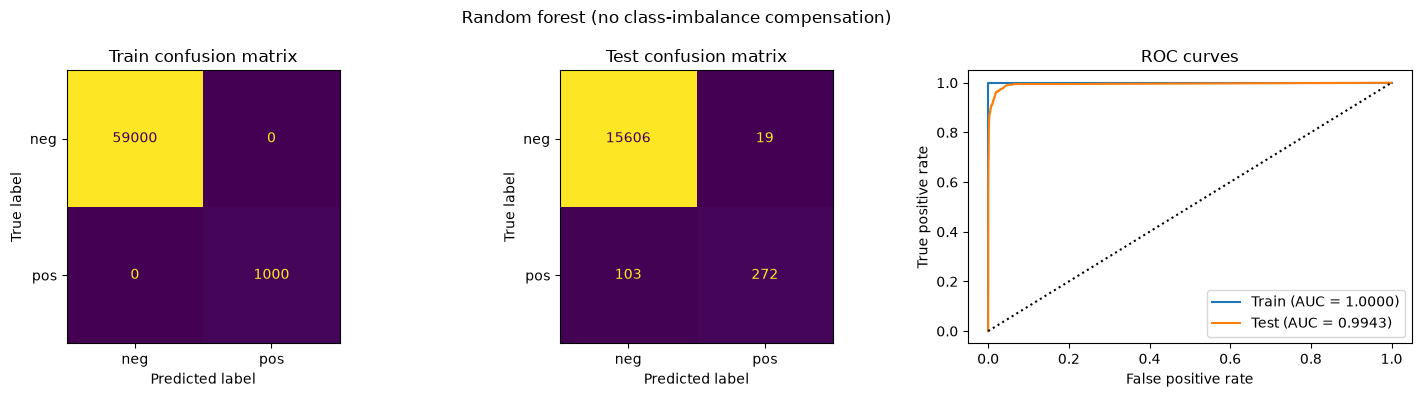

OOB error estimate: 0.00580    Test error: 0.00762


,FP,FN,Misclassification,AUC
Train,0,0,0.000000,1.000000
Test,19,103,0.007625,0.994316


In [8]:
rf = Pipeline([('impute', BatchMedianImputer()),
               ('rf', RandomForestClassifier(
                   n_estimators=500, oob_score=True,
                   random_state=SEED, n_jobs=-1))])
rf.fit(X_train, y_train)
rf_results = report('Random forest (no class-imbalance compensation)', rf,
                    X_train, y_train, X_test, y_test)
rf_oob = 1 - rf['rf'].oob_score_
rf_test = rf_results.loc['Test', 'Misclassification']
print(f'OOB error estimate: {rf_oob:.5f}    Test error: {rf_test:.5f}')
rf_results

The forest has 500 fully grown trees and no class weights. It fits the training data perfectly (no errors, AUC = 1.0). That's expected for fully grown trees and says nothing about performance on new data.

The OOB error (0.0058) is a little lower than the test error (0.0076), so OOB gives a close but slightly optimistic estimate. (OOB observations are excluded from individual trees, but the imputation statistics use the full training set.) The test set has a higher share of positives (2.3% vs. 1.7%), and almost all of the forest's test errors are missed failures (103 false negatives against 19 false positives), so a somewhat higher test error isn't surprising. The test AUC is high (0.994), so the forest ranks failing trucks above the others well, but at the 0.5 threshold it still misses more than a quarter of the 375 failures.

### (d) Research class imbalance in random forest

Ways to handle class imbalance in random forests:

- Class weights (cost-sensitive learning): give errors on the minority class a larger weight in the split criterion and in the leaf votes (`class_weight='balanced'` in scikit-learn). Chen, Liaw and Breiman (2004) call this a weighted random forest.
- Balanced random forest: grow each tree on a sample that has the same number of rows from each class, by undersampling the majority class for each tree (Chen, Liaw and Breiman, 2004).
- Resampling the data before training: oversample the minority class (randomly or with SMOTE) or undersample the majority class.
- Moving the decision threshold: predict positive when the forest's positive-class probability is above some value lower than 0.5.

I use a balanced random forest (`BalancedRandomForestClassifier` from imbalanced-learn). Each of the 500 trees is grown on 1,000 positive and 1,000 negative training rows drawn with replacement, and the other settings match (c). scikit-learn's built-in OOB score needs a second bootstrap sample (`bootstrap=True`), so I compute the OOB estimate directly: each training row is predicted only by the trees whose balanced sample didn't include it, and it's classified positive if their average probability is at least 0.5.

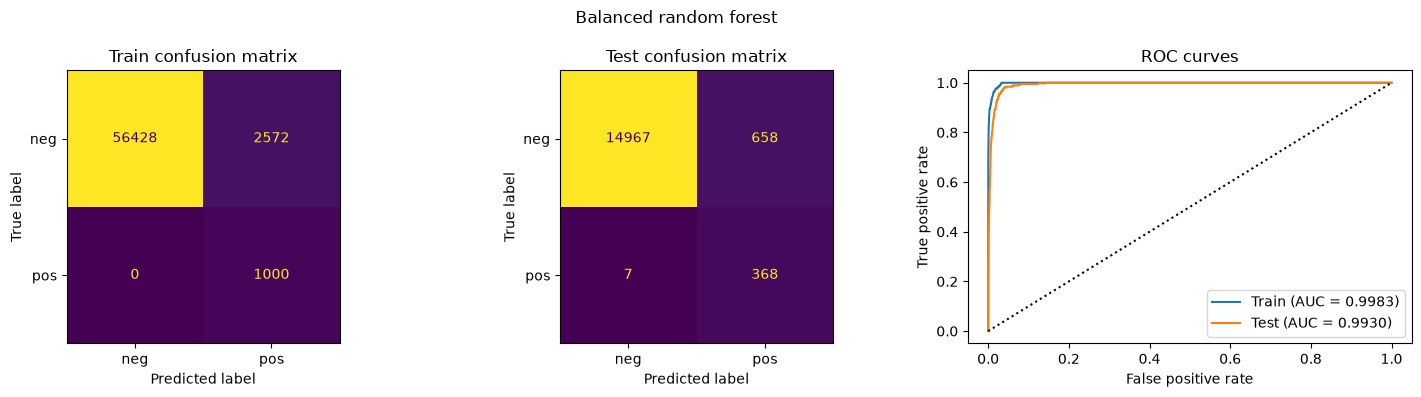

OOB error estimate: 0.04425    Test error: 0.04156


,Train error,OOB error,Test error,Train AUC,Test AUC,Test FP,Test FN
Random forest (c),0.000000,0.00580,0.007625,1.000000,0.994316,19,103
Balanced random forest (d),0.042867,0.04425,0.041563,0.998277,0.993024,658,7


In [9]:
brf = Pipeline([('impute', BatchMedianImputer()),
                ('brf', BalancedRandomForestClassifier(
                    n_estimators=500, sampling_strategy='all',
                    replacement=True, bootstrap=False,
                    random_state=SEED, n_jobs=-1))])
brf.fit(X_train, y_train)
brf_results = report('Balanced random forest', brf,
                     X_train, y_train, X_test, y_test)

# the built-in OOB score needs bootstrap=True, so score each row only with
# trees whose sample left it out
Xi = brf['impute'].transform(X_train)
votes, n_trees = np.zeros(len(y_train)), np.zeros(len(y_train))
for sampler, tree in zip(brf['brf'].samplers_, brf['brf'].estimators_):
    oob = np.ones(len(y_train), dtype=bool)
    oob[sampler.sample_indices_] = False
    votes[oob] += tree.predict_proba(Xi[oob])[:, 1]
    n_trees[oob] += 1
assert n_trees.min() > 0
brf_oob = np.mean((votes / n_trees >= 0.5) != y_train)
brf_test = brf_results.loc['Test', 'Misclassification']
print(f'OOB error estimate: {brf_oob:.5f}    Test error: {brf_test:.5f}')

compare({'Random forest (c)': (rf_results, rf_oob),
         'Balanced random forest (d)': (brf_results, brf_oob)},
        'OOB error')

Compared with (c), compensating for the imbalance changes the kind of errors rather than reducing them. On the test set the balanced forest misses only 7 of the 375 failures (103 in (c)) but raises 658 false alarms (19 in (c)). Since negatives far outnumber positives, the misclassification rate goes up from about 0.008 to about 0.042. The test AUCs are almost the same (0.994 vs. 0.993), so both forests rank trucks about equally well overall but put different trucks above the 0.5 threshold. The OOB error (0.044) is again close to the test error (0.042). Which forest is better depends on how much a missed failure costs compared with a false alarm. If missed failures are much more expensive, the balanced forest is the better choice.

### (e) XGBoost and Model Trees

The assignment suggests XGBoost for the model tree, but XGBoost's tree booster (`gbtree`) grows ordinary trees that split on one feature at a time. It doesn't fit an L1-penalized logistic regression at each node. So I use boosted trees with the logistic loss (`binary:logistic`) and an L1 penalty $\alpha$ (`reg_alpha`) on the leaf weights, with the L2 penalty switched off (`reg_lambda=0`) so that $\alpha$ is the only penalty. The other settings are fixed at 300 trees, maximum depth 6 and learning rate 0.1. Features are standardized (the scaler is fitted on training data only) so that this pipeline matches the one in (f) except for SMOTE. There's no compensation for class imbalance.

$\alpha$ is chosen from {0, 0.001, 0.01, 0.1, 1, 10, 100, 1000} by 5-fold stratified cross-validation, taking the value with the highest mean validation AUC. I use AUC rather than accuracy because accuracy is dominated by the negative class here. The CV error below is the mean misclassification rate over the five validation folds. After the search, the model with the chosen $\alpha$ is refit on the full training set.

In [10]:
alphas = [0, 0.001, 0.01, 0.1, 1, 10, 100, 1000]
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)


def xgb_search(use_smote):
    # same preprocessing in (e) and (f)
    steps = [('impute', BatchMedianImputer()),
             ('scale', StandardScaler())]
    if use_smote:
        steps.append(('smote', SMOTE(k_neighbors=5, random_state=SEED)))
    steps.append(('xgb', XGBClassifier(
        n_estimators=300, learning_rate=0.1, max_depth=6, reg_lambda=0,
        tree_method='hist', random_state=SEED, n_jobs=2)))
    scoring = {'AUC': 'roc_auc', 'accuracy': 'accuracy'}
    search = GridSearchCV(ImbPipeline(steps),
                          {'xgb__reg_alpha': alphas}, cv=folds, n_jobs=5,
                          refit='AUC', scoring=scoring)
    search.fit(X_train, y_train)
    res = search.cv_results_
    table = pd.DataFrame({'alpha': alphas,
                          'Mean CV AUC': res['mean_test_AUC'],
                          'CV error': 1 - res['mean_test_accuracy']})
    return search, table


xgb, xgb_cv = xgb_search(use_smote=False)
xgb_cv

,alpha,Mean CV AUC,CV error
0,0.000,0.987847,0.005517
1,0.001,0.987779,0.005650
2,0.010,0.987844,0.005633
3,0.100,0.988688,0.005500
4,1.000,0.988290,0.005550
5,10.000,0.988748,0.006800
6,100.000,0.981831,0.011117
7,1000.000,0.500000,0.016667


Selected alpha: 10


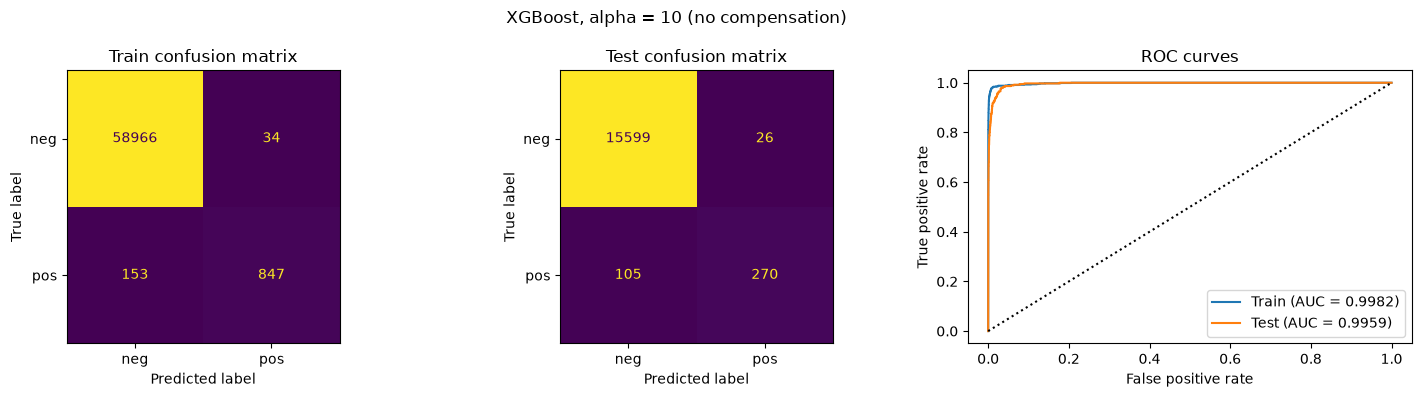

5-fold CV error: 0.00680    Test error: 0.00819


,FP,FN,Misclassification,AUC
Train,34,153,0.003117,0.998200
Test,26,105,0.008188,0.995907


In [11]:
best = xgb.best_index_
print('Selected alpha:', alphas[best])
xgb_results = report(f'XGBoost, alpha = {alphas[best]} (no compensation)',
                     xgb.best_estimator_,
                     X_train, y_train, X_test, y_test)
xgb_cv_err = xgb_cv.loc[best, 'CV error']
xgb_test = xgb_results.loc['Test', 'Misclassification']
print(f'5-fold CV error: {xgb_cv_err:.5f}    Test error: {xgb_test:.5f}')
xgb_results

$\alpha = 10$ has the highest mean CV AUC (0.9887), although every $\alpha$ from 0 to 10 gives a mean AUC within about 0.001 of it, so the choice among them matters little. At $\alpha = 1000$ the penalty shrinks every leaf weight to zero. The model then gives every truck the same probability, so AUC = 0.5 and the error equals the share of positives (0.0167). $\alpha = 10$ doesn't have the lowest CV error ($\alpha = 0.1$ does) because AUC scores how the predicted probabilities rank the trucks, while the error only depends on which side of 0.5 they fall.

The 5-fold CV error at $\alpha = 10$ (0.0068) is a little lower than the test error (0.0082), the same pattern as the OOB error in (c). Again most test errors are missed failures (105 false negatives vs. 26 false positives). The CV error may also be slightly optimistic because the same folds were used to choose $\alpha$. The training error (0.0031) is lower than both, as expected for in-sample predictions.

### (f) Use SMOTE to pre-process your data

SMOTE creates synthetic positive rows. For a positive row it picks one of its 5 nearest positive neighbours and places a new point at a random position on the line between the two. Because this relies on distances, it's applied after standardizing the features, as in (e). SMOTE is set to balance the classes 1:1. The preprocessing, XGBoost settings and $\alpha$ grid are the same as in (e), so SMOTE is the only difference.

The wrong way to cross-validate is to apply SMOTE to the whole training set and then split it into folds. Synthetic rows are built from real positives, so the validation folds would contain synthetic near-copies of positives that sit in the training folds, and they'd be balanced 1:1 instead of looking like real data. Both make the CV estimate too optimistic. The right way, used here, is to put SMOTE inside the pipeline so that in each split it's applied only to the four training folds and the validation fold is left untouched. The test set is never resampled. After $\alpha$ is chosen, the final model is refit on the full 60,000-row training set, where SMOTE brings both classes to 59,000 (printed below). Training metrics are computed on the original 60,000 rows, not on the synthetic ones.

In [12]:
xgbs, xgbs_cv = xgb_search(use_smote=True)
xgbs_cv

,alpha,Mean CV AUC,CV error
0,0.000,0.986678,0.008250
1,0.001,0.986146,0.008167
2,0.010,0.986614,0.008433
3,0.100,0.986381,0.008333
4,1.000,0.986865,0.008067
5,10.000,0.987618,0.010683
6,100.000,0.986338,0.022167
7,1000.000,0.980182,0.043350


Selected alpha: 10
Class counts after SMOTE on the full training set: [59000 59000]


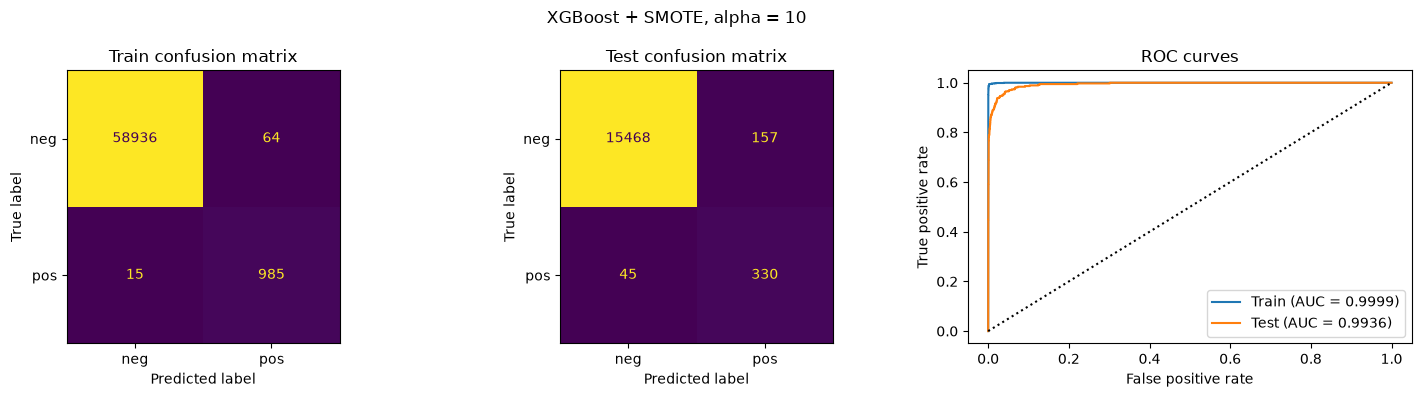

5-fold CV error: 0.01068    Test error: 0.01263


,Train error,CV error,Test error,Train AUC,Test AUC,Test FP,Test FN
XGBoost (e),0.003117,0.006800,0.008188,0.998200,0.995907,26,105
XGBoost + SMOTE (f),0.001317,0.010683,0.012625,0.999859,0.993557,157,45


In [13]:
best_s = xgbs.best_index_
print('Selected alpha:', alphas[best_s])
_, y_res = xgbs.best_estimator_[:-1].fit_resample(X_train, y_train)
print('Class counts after SMOTE on the full training set:',
      np.bincount(y_res))
xgbs_results = report(f'XGBoost + SMOTE, alpha = {alphas[best_s]}',
                      xgbs.best_estimator_,
                      X_train, y_train, X_test, y_test)
xgbs_cv_err = xgbs_cv.loc[best_s, 'CV error']
xgbs_test = xgbs_results.loc['Test', 'Misclassification']
print(f'5-fold CV error: {xgbs_cv_err:.5f}',
      f'   Test error: {xgbs_test:.5f}')

compare({'XGBoost (e)': (xgb_results, xgb_cv_err),
         'XGBoost + SMOTE (f)': (xgbs_results, xgbs_cv_err)}, 'CV error')

$\alpha = 10$ is selected again (mean CV AUC 0.9876). The CV error (0.0107) is a little lower than the test error (0.0126), the same pattern as in (e).

Against the uncompensated model in (e), SMOTE catches more failures on the test set (45 missed instead of 105) but raises more false alarms (157 instead of 26). Misclassification goes up on both CV (0.0068 to 0.0107) and test (0.0082 to 0.0126), and the test AUC drops slightly (0.9959 to 0.9936). So SMOTE makes overall accuracy and AUC slightly worse here and trades missed failures for false alarms, much like the balanced forest in (d). That trade is only worth it if a missed failure costs much more than a false alarm. This comparison uses test-set medians as specified in footnote 1, so the conclusion depends on that preprocessing convention.

## 2. ISLR 6.6.3

Increasing $s$ from 0 loosens the constraint $\sum_j |\beta_j| \le s$. At $s = 0$ all slopes are forced to 0 (an intercept-only model). Once $s$ is large enough, the least squares solution is allowed and the lasso becomes ordinary least squares. So increasing $s$ makes the model steadily more flexible.

**(a) Training RSS: iv. Steadily decrease.** Each larger $s$ allows every coefficient vector that was allowed before, plus more, so the smallest achievable training RSS can only go down (it levels off once the least squares fit is reached).

**(b) Test RSS: ii. Decrease initially, then increase in a U shape.** At first, letting coefficients move away from 0 captures real signal and test RSS drops. With too much freedom the model starts fitting noise in the training data and test RSS rises again.

**(c) Variance: iii. Steadily increase.** At $s = 0$, only the intercept is estimated. Relaxing the constraint typically increases the fitted model's sensitivity to the training sample, so variance grows.

**(d) Squared bias: iv. Steadily decrease.** A more flexible model can get closer to the true relationship, so bias falls as $s$ grows.

**(e) Irreducible error: v. Remain constant.** The irreducible error is the variance of the noise $\varepsilon$, which belongs to the data, not the model, so it doesn't depend on $s$.

Parts (b) to (d) describe the usual pattern the textbook has in mind. They aren't guaranteed for every data set.

## 3. ISLR 6.6.5

Write $x_{11} = x_{12} = x$, so $x_{21} = x_{22} = -x$, and $y_1 = y$, $y_2 = -y$. With $\hat\beta_0 = 0$, both observations give the same squared residual: $(y - x\beta_1 - x\beta_2)^2 = (-y + x\beta_1 + x\beta_2)^2$.

**(a) Ridge:**
$$\begin{aligned}
&\min_{\beta_1, \beta_2}\; (y_1 - \beta_1 x_{11} - \beta_2 x_{12})^2 + (y_2 - \beta_1 x_{21} - \beta_2 x_{22})^2 + \lambda(\beta_1^2 + \beta_2^2) \\
&= \min_{\beta_1, \beta_2}\; 2\big(y - x(\beta_1 + \beta_2)\big)^2 + \lambda(\beta_1^2 + \beta_2^2).
\end{aligned}$$

**(b)** Setting the derivatives with respect to $\beta_1$ and $\beta_2$ to zero:
$$-4x\big(y - x(\beta_1 + \beta_2)\big) + 2\lambda\beta_1 = 0, \qquad -4x\big(y - x(\beta_1 + \beta_2)\big) + 2\lambda\beta_2 = 0.$$
The first terms are identical, so subtracting gives $2\lambda(\beta_1 - \beta_2) = 0$, i.e. $\hat\beta_1 = \hat\beta_2$ for $\lambda > 0$. The objective is strictly convex for $\lambda > 0$, so this is the unique solution: $\hat\beta_1 = \hat\beta_2 = \dfrac{2xy}{4x^2 + \lambda}$.

**(c) Lasso:**
$$\min_{\beta_1, \beta_2}\; 2\big(y - x(\beta_1 + \beta_2)\big)^2 + \lambda\big(|\beta_1| + |\beta_2|\big).$$

**(d)** Assume $x \ne 0$ and $\lambda > 0$ (if $x = 0$ and $\lambda > 0$, the RSS doesn't depend on the coefficients and the only solution is $\hat\beta_1 = \hat\beta_2 = 0$). The RSS part depends only on the sum $c = \beta_1 + \beta_2$. For a fixed sum, $|\beta_1| + |\beta_2| \ge |c|$, with equality whenever $\beta_1$ and $\beta_2$ have the same sign as $c$ (or are 0). So the best value is reached by first choosing the best sum,
$$c^* = \operatorname{sign}(y/x)\,\max\!\Big(|y/x| - \frac{\lambda}{4x^2},\, 0\Big),$$
and then splitting it in any way where both coefficients have the same sign as $c^*$. The solutions are all points on the line segment
$$\hat\beta_1 + \hat\beta_2 = c^*, \quad \hat\beta_1, \hat\beta_2 \ge 0 \;(\text{if } c^* > 0) \text{ or } \le 0 \;(\text{if } c^* < 0),$$
from $(c^*, 0)$ to $(0, c^*)$, so there are infinitely many. Geometrically, the RSS contours are the lines $\beta_1 + \beta_2 = \text{constant}$. These are parallel to an edge of the lasso diamond $|\beta_1| + |\beta_2| \le s$, so a contour touches the diamond along a whole edge instead of at a single corner. The one exception is $\lambda \ge 4|xy|$: then $c^* = 0$ and the only solution is $\hat\beta_1 = \hat\beta_2 = 0$.

## 4. ISLR 8.4.5

With majority vote, 6 of the 10 estimates (0.55, 0.6, 0.6, 0.65, 0.7, 0.75) are above 0.5, so 6 trees vote Red and 4 vote Green. The final classification is **Red**.

With the average probability, the estimates sum to 4.5, so the average is $4.5 / 10 = 0.45 < 0.5$. The final classification is **Green**.

The two approaches disagree because the four Green votes are much more confident (P(Red) of only 0.1 to 0.2) than the six Red votes (P(Red) of 0.55 to 0.75).

## 5. ISLR 9.7.3

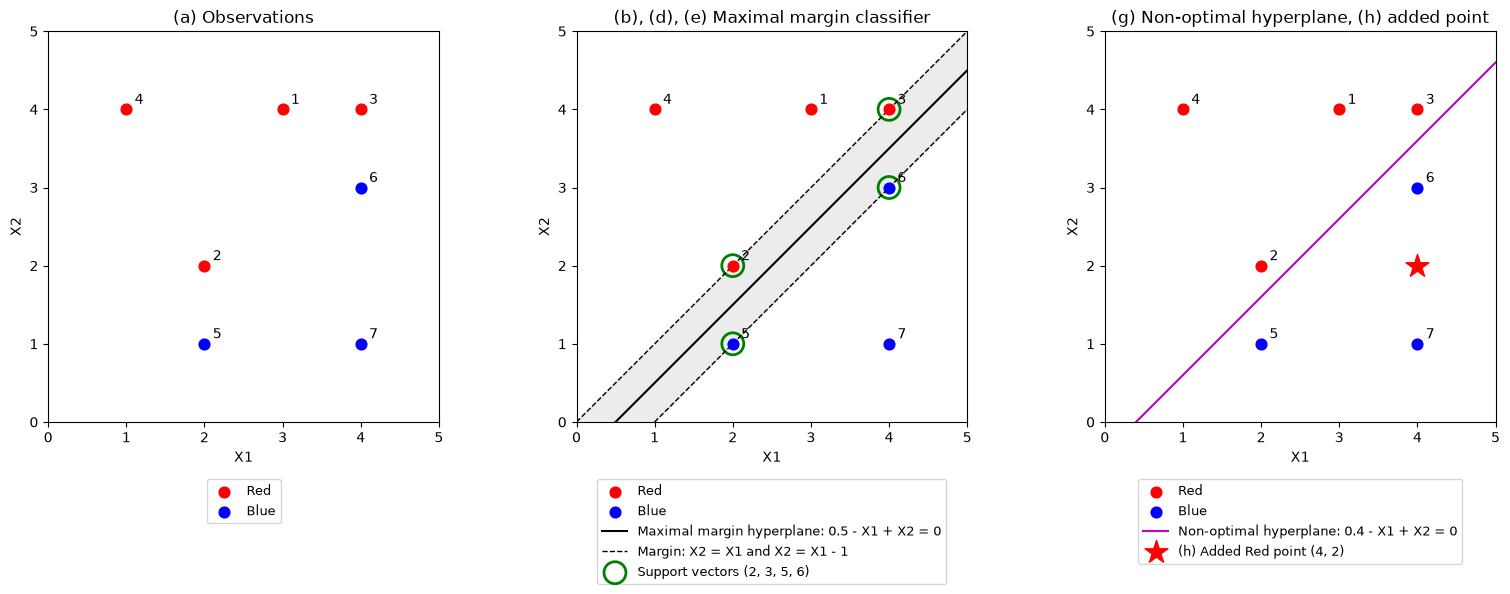

In [14]:
pts = np.array([[3, 4], [2, 2], [4, 4], [1, 4], [2, 1], [4, 3], [4, 1]])
red = np.array([1, 1, 1, 1, 0, 0, 0], dtype=bool)
xs = np.array([0, 5])
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
for ax in axes:
    ax.scatter(*pts[red].T, color='red', s=60, label='Red', zorder=3)
    ax.scatter(*pts[~red].T, color='blue', s=60, label='Blue', zorder=3)
    for i, (a, b) in enumerate(pts, 1):
        ax.annotate(str(i), (a, b), xytext=(6, 4),
                    textcoords='offset points')
    ax.set(xlim=(0, 5), ylim=(0, 5), xlabel='X1', ylabel='X2',
           aspect='equal')
axes[0].set_title('(a) Observations')
axes[1].plot(xs, xs - 0.5, 'k',
             label='Maximal margin hyperplane: 0.5 - X1 + X2 = 0')
axes[1].plot(xs, xs, 'k--', lw=1, label='Margin: X2 = X1 and X2 = X1 - 1')
axes[1].plot(xs, xs - 1, 'k--', lw=1)
axes[1].fill_between(xs, xs - 1, xs, color='gray', alpha=0.15)
axes[1].scatter(*pts[[1, 2, 4, 5]].T, s=250, facecolors='none',
                edgecolors='green', lw=2,
                label='Support vectors (2, 3, 5, 6)')
axes[1].set_title('(b), (d), (e) Maximal margin classifier')
axes[2].plot(xs, xs - 0.4, 'm',
             label='Non-optimal hyperplane: 0.4 - X1 + X2 = 0')
axes[2].scatter([4], [2], color='red', marker='*', s=300, zorder=4,
                label='(h) Added Red point (4, 2)')
axes[2].set_title('(g) Non-optimal hyperplane, (h) added point')
for ax in axes:
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.13), fontsize=9)
plt.tight_layout()
plt.show()

**(a)** See the left panel.

**(b)** The closest Red points, 2 = (2, 2) and 3 = (4, 4), lie on the line $X_2 = X_1$, and the closest Blue points, 5 = (2, 1) and 6 = (4, 3), lie on the parallel line $X_2 = X_1 - 1$. The widest gap between the classes is the strip between these two lines, and the maximal margin hyperplane runs through its middle (middle panel):
$$X_2 = X_1 - 0.5, \quad\text{i.e.}\quad 0.5 - X_1 + X_2 = 0.$$

**(c)** Classify to Red if $0.5 - X_1 + X_2 > 0$, and classify to Blue otherwise, so $\beta_0 = 0.5$, $\beta_1 = -1$, $\beta_2 = 1$. (Any positive multiple gives the same rule; dividing by $\sqrt2$ makes $\beta_1^2 + \beta_2^2 = 1$.) Check: observation 1 gives $0.5 - 3 + 4 = 1.5 > 0$ (Red) and observation 7 gives $0.5 - 4 + 1 = -2.5 < 0$ (Blue).

**(d)** The margin is the shaded strip in the middle panel, between the dashed lines $X_2 = X_1$ and $X_2 = X_1 - 1$. The distance from the hyperplane to either dashed line is $M = \dfrac{0.5}{\sqrt{1^2 + 1^2}} = \dfrac{\sqrt2}{4} \approx 0.354$.

**(e)** The support vectors are observations 2, 3 (Red) and 5, 6 (Blue), the points that lie on the margin (circled in green).

**(f)** Observation 7 = (4, 1) is at distance $|0.5 - 4 + 1| / \sqrt2 \approx 1.77$ from the hyperplane, well outside the margin, and it isn't a support vector. The maximal margin hyperplane depends only on the support vectors, so moving observation 7 slightly (while keeping it outside the margin) doesn't change it.

**(g)** The magenta line in the right panel, $0.4 - X_1 + X_2 = 0$ (i.e. $X_2 = X_1 - 0.4$), also separates the two classes, but it's closer to Red points 2 and 3. Its margin is $0.4 / \sqrt2 \approx 0.28 < 0.354$, so it isn't optimal.

**(h)** Add a Red observation at (4, 2) (the star in the right panel). It lies on the segment between Blue points 6 = (4, 3) and 7 = (4, 1). Any line with both of those Blue points on one side also has the whole segment between them on that side, so no line can separate (4, 2) from the Blue points, and the classes are no longer separable by a hyperplane.

## References

- https://scikit-learn.org/stable/modules/impute.html
- https://statistics.berkeley.edu/tech-reports/666
- https://imbalanced-learn.org/stable/common_pitfalls.html

*AI use: Claude Code (Anthropic) was used to edit this notebook from my own script and notes*